# Load data

In [52]:
import pandas as pd  # veri yükleme

df = pd.read_csv("Salary_Data.csv")
df.head() # veri setinin ilk 5 satırını görüntüleme

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [53]:
df.describe() # veri setinin istatistiksel özelliklerini görüntüleme

,Age,Years of Experience,Salary
count,6702.000000,6701.000000,6699.000000
mean,33.620859,8.094687,115326.964771
std,7.614633,6.059003,52786.183911
min,21.000000,0.000000,350.000000
25%,28.000000,3.000000,70000.000000
50%,32.000000,7.000000,115000.000000
75%,38.000000,12.000000,160000.000000
max,62.000000,34.000000,250000.000000


In [54]:
df.info() # veri setinin bilgilerini görüntüleme

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   object 
 2   Education Level      6701 non-null   object 
 3   Job Title            6702 non-null   object 
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), object(3)
memory usage: 314.4+ KB


In [55]:
df.nunique() # veri setindeki unique değerleri görüntüleme

Age                     41
Gender                   3
Education Level          7
Job Title              193
Years of Experience     37
Salary                 444
dtype: int64

In [56]:
df["Gender"].value_counts() # Other değerinin varlığı ile yanlıs girilen veri etiketi olmadığı doğrulandı

Gender
Male      3674
Female    3014
Other       14
Name: count, dtype: int64

In [57]:
df.isnull().sum()/len(df) # null değerlerin oranını görüntüleme

Age                    0.000298
Gender                 0.000298
Education Level        0.000447
Job Title              0.000298
Years of Experience    0.000447
Salary                 0.000746
dtype: float64

In [58]:
df.dropna(inplace=True) # null değerleri silme ve veri setini güncelleme

In [59]:
from sklearn.preprocessing import LabelEncoder  # etiket kodlama yani sayısal olmayan verileri sayısal yapmak için kullanılır

le = LabelEncoder()
df["Gender"] = le.fit_transform(df["Gender"])
df["Education Level"] = le.fit_transform(df["Education Level"])
df.head()




,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,1,0,Software Engineer,5.0,90000.0
1,28.0,0,3,Data Analyst,3.0,65000.0
2,45.0,1,5,Senior Manager,15.0,150000.0
3,36.0,0,0,Sales Associate,7.0,60000.0
4,52.0,1,3,Director,20.0,200000.0


In [60]:
col = "Job Title"
threshold = 5  # bu sayıdan az geçen sınıflar "rare"

counts = df[col].value_counts()
rare = counts[counts < threshold]

# sınıf adları object olarak
rare_classes = rare.index.astype(object)
print(rare_classes)
print(type(rare_classes[0]))  # <class 'str'>

# sınıf adı + kaç kez geçtiği
rare_df = rare.rename_axis(col).reset_index(name="count")
rare_df
df[col] = df[col].replace(rare_classes, "Other")

Index(['Senior Operations Coordinator', 'Senior Business Development Manager',
       'Senior Data Engineer', 'Junior Product Manager',
       'Senior Marketing Specialist', 'Senior Marketing Coordinator',
       'Juniour HR Generalist', 'Senior Financial Advisor',
       'Junior Operations Manager', 'Junior Accountant',
       ...
       'Senior Account Executive', 'Director of Business Development',
       'Junior Financial Advisor', 'Junior Operations Coordinator',
       'Senior HR Specialist', 'Junior Research Scientist',
       'Senior Product Development Manager', 'Junior Social Media Specialist',
       'Senior Software Architect', 'Social Media Man'],
      dtype='object', name='Job Title', length=117)
<class 'str'>


In [61]:
rare_df.describe() # rare değerlerin istatistiksel özelliklerini görüntüleme

,count
count,117.000000
mean,1.495726
std,0.847145
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,4.000000


In [62]:
df.head() # rare değerlerin görüntülenmesi

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,1,0,Software Engineer,5.0,90000.0
1,28.0,0,3,Data Analyst,3.0,65000.0
2,45.0,1,5,Other,15.0,150000.0
3,36.0,0,0,Sales Associate,7.0,60000.0
4,52.0,1,3,Other,20.0,200000.0


In [ ]:
df["Job Title"] = le.fit_transform(df["Job Title"])  # Job Title sütununu kodlama ve rare değerleri Other sınıfına dönüştürme

df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,1,0,72,5.0,90000.0
1,28.0,0,3,3,3.0,65000.0
2,45.0,1,5,41,15.0,150000.0
3,36.0,0,0,48,7.0,60000.0
4,52.0,1,3,41,20.0,200000.0


In [64]:
# Cinsiyet ve Eğitim seviyesini sayılara çevirme
df["Gender"] = le.fit_transform(df["Gender"])
df["Education Level"] = le.fit_transform(df["Education Level"])


In [65]:
df.corr()       # veri setindeki değişkenler arasındaki korelasyonu görüntüleme 

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
Age,1.000000,0.120672,0.534761,0.172147,0.937725,0.728061
Gender,0.120672,1.000000,-0.041675,0.075707,0.105656,0.127276
Education Level,0.534761,-0.041675,1.000000,0.033936,0.532957,0.472839
Job Title,0.172147,0.075707,0.033936,1.000000,0.136179,0.066254
Years of Experience,0.937725,0.105656,0.532957,0.136179,1.000000,0.808968
Salary,0.728061,0.127276,0.472839,0.066254,0.808968,1.000000


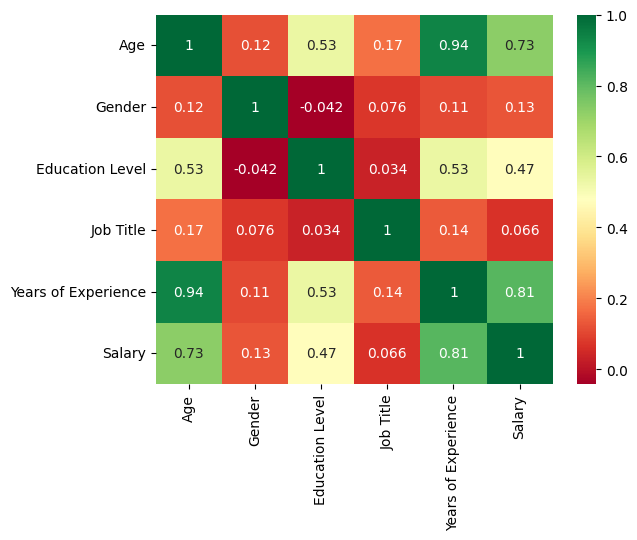

In [66]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(df.corr(), annot=True, cmap="RdYlGn")
plt.show()





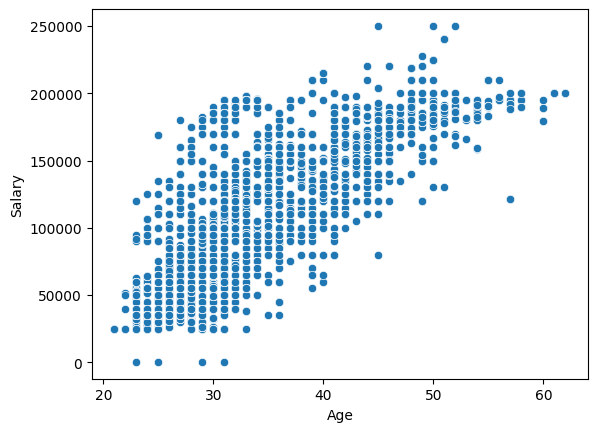

In [67]:
# scatter plot
sns.scatterplot(x="Age", y="Salary", data=df)
plt.show()

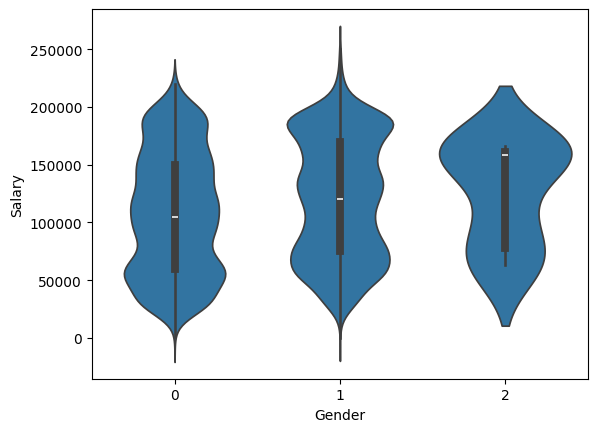

In [68]:
# violin plot gender salary
sns.violinplot(x="Gender", y="Salary", data=df)
plt.show()

In [69]:
# outlier detection with iqr threshold
q1 = df["Salary"].quantile(0.25)
q3 = df["Salary"].quantile(0.75)
iqr = q3 - q1
threshold = 1.5 * iqr
lower_bound = q1 - threshold
upper_bound = q3 + threshold



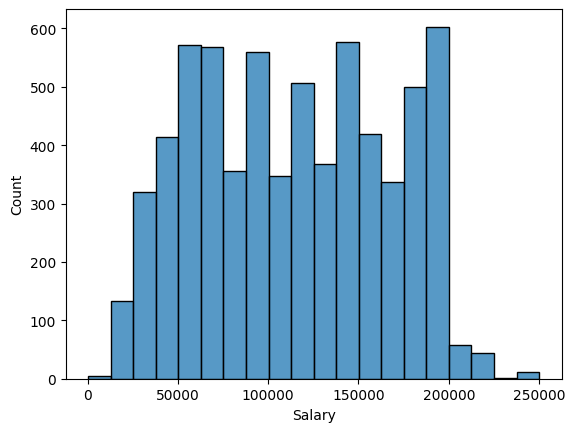

In [70]:
#remove outliers
df = df[df["Salary"] > lower_bound]
df = df[df["Salary"] < upper_bound]

# histogram
sns.histplot(df["Salary"], bins=20)
plt.show()


In [71]:
df.head()



,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,1,0,72,5.0,90000.0
1,28.0,0,3,3,3.0,65000.0
2,45.0,1,5,41,15.0,150000.0
3,36.0,0,0,48,7.0,60000.0
4,52.0,1,3,41,20.0,200000.0


In [72]:
df.drop(columns=["Age"], inplace=True)

In [73]:
df.head()


,Gender,Education Level,Job Title,Years of Experience,Salary
0,1,0,72,5.0,90000.0
1,0,3,3,3.0,65000.0
2,1,5,41,15.0,150000.0
3,0,0,48,7.0,60000.0
4,1,3,41,20.0,200000.0


In [75]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Salary"])
y = df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [76]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [77]:
X

,Gender,Education Level,Job Title,Years of Experience
0,1,0,72,5.0
1,0,3,3,3.0
2,1,5,41,15.0
3,0,0,48,7.0
4,1,3,41,20.0
...,...,...,...,...
6699,0,5,10,20.0
6700,1,2,48,3.0
6701,0,1,13,4.0
6702,1,4,39,14.0


In [78]:
X_train

array([[ 0.89507087,  0.79000963,  0.76839877,  0.3157382 ],
       [-1.09736357,  0.79000963, -1.4942569 ,  0.3157382 ],
       [-1.09736357,  1.34001893,  0.33174592,  0.64806809],
       ...,
       [ 0.89507087, -0.86001828, -0.14460264, -1.17974629],
       [ 0.89507087, -0.86001828, -0.14460264, -1.17974629],
       [-1.09736357, -1.41002758, -1.37516976, -1.01358135]],
      shape=(5358, 4))

In [79]:
from sklearn.linear_model import LinearRegression

# 1. Modeli başlatıyoruz
model = LinearRegression()

# 2. Eğitim verileriyle modeli eğitiyoruz (Örüntüyü öğreniyor)
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [80]:
X_test

array([[ 0.89507087,  0.79000963, -1.4942569 ,  0.14957326],
       [-1.09736357,  0.79000963, -0.8988212 , -0.68125146],
       [-1.09736357,  0.24000033, -1.37516976, -1.17974629],
       ...,
       [-1.09736357,  1.34001893, -1.09729976, -0.34892157],
       [-1.09736357, -1.41002758,  0.13326736,  0.3157382 ],
       [ 0.89507087, -0.86001828,  1.32413876, -0.84741641]],
      shape=(1340, 4))

In [81]:
y_pred = model.predict(X_test)

y_pred


array([129578.31604159,  89473.23542842,  68427.84542247, ...,
       105247.9382738 , 121171.75576072,  77183.38059991], shape=(1340,))

In [82]:
from sklearn.metrics import mean_absolute_error, r2_score

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(r2)
print(mae)


0.6658952039904362
24455.862763241144


In [87]:
from sklearn.ensemble import GradientBoostingRegressor

model = GradientBoostingRegressor(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(r2)
print(mae)

0.9285964580733042
10541.914859792003


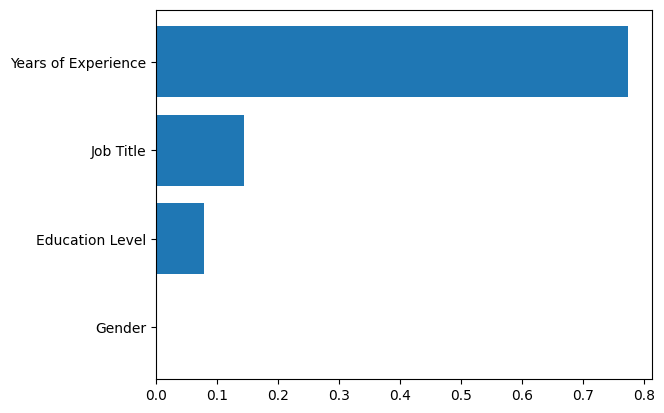

In [ ]:
import matplotlib.pyplot as plt  //hangi değişken maaşı daha fazla etkiliyor

importances = model.feature_importances_
features = X.columns

plt.barh(features, importances)
plt.show()